# 1. Exoplanet Candidate Classification

In this notebook, we will be building machine learning models that will classify the Kepler Objects of Interest into confirmed exoplanets and false positives.

We will be evaluating both linear and tree-based classifiers and optimizing the best performing model.

The dataset consists of 7,587 rows of data and 12 numerical predictive features. The host star IDs have been preserved to enable grouping while splitting the data.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import joblib

from scipy.stats import randint

from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    RandomizedSearchCV,
    GridSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Loading and Preparing Dataset

Load the prepared dataset and split the predictors, target, and host star IDs.

The target is binary; `0` corresponds to a false positive, while `1` corresponds to a planet. The host star ID (`kepid`) is not a predictor.

In [2]:
DATA_PATH = Path("../data/kepler_binary.csv")

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["target", "kepid"])
y = df["target"]
groups = df["kepid"]

print("Dataset shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Number of unique host stars:", groups.nunique())

Dataset shape: (7587, 14)
Feature matrix shape: (7587, 12)
Target shape: (7587,)
Number of unique host stars: 6641


## 3. Training, Validation, and Testing Datasets

The data is split into training, validation, and test datasets (approximately 60%, 20%, and 20%, respectively).

Group splitting is done by using `kepid` so that all measurements from the same host star will be in the same subset.

In [3]:
from sklearn.model_selection import GroupShuffleSplit

split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.40,
    random_state=42
)

train_idx, temp_idx = next(
    split_1.split(X, y, groups=groups)
)

split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative_idx, test_relative_idx = next(
    split_2.split(
        X.iloc[temp_idx],
        y.iloc[temp_idx],
        groups=groups.iloc[temp_idx]
    )
)

val_idx = temp_idx[val_relative_idx]
test_idx = temp_idx[test_relative_idx]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (4540, 12)
Validation set: (1546, 12)
Test set: (1501, 12)


In [4]:
train_stars = set(groups.iloc[train_idx])
val_stars = set(groups.iloc[val_idx])
test_stars = set(groups.iloc[test_idx])

print("Train-validation overlap:", len(train_stars & val_stars))
print("Train-test overlap:", len(train_stars & test_stars))
print("Validation-test overlap:", len(val_stars & test_stars))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


## 4. Analyzing the Splits of Data

We analyze the number of observations and the proportions of each class to evaluate the target variable split distribution.

In [5]:
splits = {
    "Training": y_train,
    "Validation": y_val,
    "Test": y_test
}

for name, target in splits.items():
    print(f"\n{name} set")
    print("Observations:", len(target))
    print("Class proportions:")
    print(target.value_counts(normalize=True).sort_index().round(3))


Training set
Observations: 4540
Class proportions:
target
0    0.642
1    0.358
Name: proportion, dtype: float64

Validation set
Observations: 1546
Class proportions:
target
0    0.607
1    0.393
Name: proportion, dtype: float64

Test set
Observations: 1501
Class proportions:
target
0    0.658
1    0.342
Name: proportion, dtype: float64


## 5. Preprocessing

The following steps are followed for preprocessing:

- **Median Imputation:** Fills missing values with the median of the corresponding feature.
- **Standardization:** Scales features to have approximately zero mean and unit variance.

The parameters for preprocessing are estimated using the training data and then used on the validation and testing subsets.

In [6]:
numeric_features = X.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        )
    ]
)

## 6. Baseline Model

A `DummyClassifier` strategy with `most_frequent` is chosen as the baseline model. This classifier predicts the most common class from the training subset, serving as a benchmark for comparing our machine learning models.

In [7]:
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_val)

print("Baseline accuracy:", accuracy_score(y_val, baseline_predictions))
print("\nClassification report:")
print(classification_report(y_val, baseline_predictions, zero_division=0))

Baseline accuracy: 0.6067270375161707

Classification report:
              precision    recall  f1-score   support

           0       0.61      1.00      0.76       938
           1       0.00      0.00      0.00       608

    accuracy                           0.61      1546
   macro avg       0.30      0.50      0.38      1546
weighted avg       0.37      0.61      0.46      1546



## 7. Evaluation Metrics

Evaluation of the models will be done based on accuracy, precision, recall, F1-score, and ROC-AUC.

The key metrics we consider are the F1-score of class 1 (confirmed exoplanets) and ROC-AUC to measure the capacity of the models to recognize confirmed candidates and differentiate between the classes.

## 8. Model 1 - Logistic Regression

Logistic Regression model is trained through logarithmic transformation of some skewed variables.

In [8]:
skewness = X_train.skew().sort_values(ascending=False)

feature_stats = pd.DataFrame({
    "Skewness": skewness,
    "Minimum": X_train.min(),
    "Maximum": X_train.max()
})

display(feature_stats)

,Skewness,Minimum,Maximum
koi_depth,4.803169,0.80000,1.541400e+06
koi_duration,6.389215,0.10460,1.385400e+02
koi_impact,24.154344,0.00000,1.008060e+02
koi_insol,37.478984,0.02000,1.094755e+07
koi_kepmag,-0.736045,6.96600,1.948500e+01
koi_model_snr,4.556591,0.00000,8.616100e+03
koi_period,3.108695,0.29363,1.064268e+03
koi_prad,54.659741,0.18000,2.003460e+05
koi_slogg,-3.674630,0.04700,5.283000e+00
koi_srad,19.255454,0.11600,2.299080e+02


In [9]:
log_features = [
    "koi_depth",
    "koi_duration",
    "koi_impact",
    "koi_insol",
    "koi_model_snr",
    "koi_period",
    "koi_prad",
    "koi_srad",
    "koi_teq"
]

other_features = [
    col for col in X_train.columns
    if col not in log_features
]

In [10]:
log_preprocessor = ColumnTransformer(
    transformers=[
        (
            "log_num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("log", FunctionTransformer(np.log1p)),
                ("scaler", StandardScaler())
            ]),
            log_features
        ),
        (
            "other_num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            other_features
        )
    ]
)

In [11]:
logistic_model = Pipeline([
    ("preprocessor", log_preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_num', ...), ('other_num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different 

In [12]:
logistic_predictions = logistic_model.predict(X_val)
logistic_probabilities = logistic_model.predict_proba(X_val)[:, 1]

In [13]:
print("Accuracy:", accuracy_score(y_val, logistic_predictions))
print("Precision (class 1):", precision_score(y_val, logistic_predictions))
print("Recall (class 1):", recall_score(y_val, logistic_predictions))
print("F1-score (class 1):", f1_score(y_val, logistic_predictions))
print("ROC-AUC:", roc_auc_score(y_val, logistic_probabilities))

print("\nClassification report:")
print(classification_report(y_val, logistic_predictions))

Accuracy: 0.8395860284605433
Precision (class 1): 0.7931596091205212
Recall (class 1): 0.8009868421052632
F1-score (class 1): 0.7970540098199672
ROC-AUC: 0.912392338121423

Classification report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.87       938
           1       0.79      0.80      0.80       608

    accuracy                           0.84      1546
   macro avg       0.83      0.83      0.83      1546
weighted avg       0.84      0.84      0.84      1546



### Logistic Regression Hyperparameter Tuning

We use grid search with 5-fold group cross-validation to find the best regularization parameter (`C`).

In [14]:
logistic_pipeline = Pipeline([
    ("preprocessor", log_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid={
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    },
    scoring="f1",
    cv=GroupKFold(n_splits=5),
    n_jobs=-1
)

logistic_search.fit(
    X_train,
    y_train,
    groups=groups.loc[X_train.index]
)

print("Best parameters:", logistic_search.best_params_)
print("Best CV F1-score:", logistic_search.best_score_)

Best parameters: {'classifier__C': 10}
Best CV F1-score: 0.7947839420967464


In [15]:
tuned_logistic_model = logistic_search.best_estimator_

tuned_logistic_predictions = tuned_logistic_model.predict(X_val)
tuned_logistic_probabilities = tuned_logistic_model.predict_proba(X_val)[:, 1]

print("Tuned Logistic Regression")
print("Accuracy:", accuracy_score(y_val, tuned_logistic_predictions))
print("Precision:", precision_score(y_val, tuned_logistic_predictions))
print("Recall:", recall_score(y_val, tuned_logistic_predictions))
print("F1-score:", f1_score(y_val, tuned_logistic_predictions))
print("ROC-AUC:", roc_auc_score(y_val, tuned_logistic_probabilities))

Tuned Logistic Regression
Accuracy: 0.8357050452781372
Precision: 0.7882736156351792
Recall: 0.7960526315789473
F1-score: 0.7921440261865794
ROC-AUC: 0.9141510492649534


## 9. Model 2 – Decision Tree Classifier

As our first tree-based model, we create a Decision Tree classifier.

In [16]:
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_val)
tree_probabilities = tree_model.predict_proba(X_val)[:, 1]

In [17]:
print("Accuracy:", accuracy_score(y_val, tree_predictions))
print("Precision (class 1):", precision_score(y_val, tree_predictions))
print("Recall (class 1):", recall_score(y_val, tree_predictions))
print("F1-score (class 1):", f1_score(y_val, tree_predictions))
print("ROC-AUC:", roc_auc_score(y_val, tree_probabilities))

print("\nClassification report:")
print(classification_report(y_val, tree_predictions))

Accuracy: 0.8816300129366106
Precision (class 1): 0.8657487091222031
Recall (class 1): 0.8273026315789473
F1-score (class 1): 0.8460891505466779
ROC-AUC: 0.872073490629559

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.92      0.90       938
           1       0.87      0.83      0.85       608

    accuracy                           0.88      1546
   macro avg       0.88      0.87      0.87      1546
weighted avg       0.88      0.88      0.88      1546



### Decision Tree Hyperparameter Tuning

We use randomized search with 5-fold group cross-validation to optimize the tree's complexity and reduce overfitting.

In [18]:
tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

tree_param_distributions = {
    "classifier__max_depth": [None, 5, 10, 20, 30, 40],
    "classifier__min_samples_split": randint(2, 21),
    "classifier__min_samples_leaf": randint(1, 11),
    "classifier__criterion": ["gini", "entropy", "log_loss"]
}

tree_search = RandomizedSearchCV(
    estimator=tree_pipeline,
    param_distributions=tree_param_distributions,
    n_iter=30,
    scoring="f1",
    cv=GroupKFold(n_splits=5),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

tree_search.fit(
    X_train,
    y_train,
    groups=groups.loc[X_train.index]
)

print("Best parameters:", tree_search.best_params_)
print("Best CV F1-score:", tree_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 7, 'classifier__min_samples_split': 12}
Best CV F1-score: 0.8538386236151407


In [19]:
tuned_tree_model = tree_search.best_estimator_

tuned_tree_predictions = tuned_tree_model.predict(X_val)
tuned_tree_probabilities = tuned_tree_model.predict_proba(X_val)[:, 1]

print("Tuned Decision Tree")
print("Accuracy:", accuracy_score(y_val, tuned_tree_predictions))
print("Precision:", precision_score(y_val, tuned_tree_predictions))
print("Recall:", recall_score(y_val, tuned_tree_predictions))
print("F1-score:", f1_score(y_val, tuned_tree_predictions))
print("ROC-AUC:", roc_auc_score(y_val, tuned_tree_probabilities))

Tuned Decision Tree
Accuracy: 0.9016817593790427
Precision: 0.8607594936708861
Recall: 0.8947368421052632
F1-score: 0.8774193548387097
ROC-AUC: 0.9420598487824037


## 10. Model 3 – Random Forest

First, we fit the default Random Forest algorithm and then tune the hyperparameters.

In [20]:
forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_val)
forest_probabilities = forest_model.predict_proba(X_val)[:, 1]

In [21]:
print("Accuracy:", accuracy_score(y_val, forest_predictions))
print("Precision (class 1):", precision_score(y_val, forest_predictions))
print("Recall (class 1):", recall_score(y_val, forest_predictions))
print("F1-score (class 1):", f1_score(y_val, forest_predictions))
print("ROC-AUC:", roc_auc_score(y_val, forest_probabilities))

print("\nClassification report:")
print(classification_report(y_val, forest_predictions))

Accuracy: 0.9146183699870634
Precision (class 1): 0.9061433447098977
Recall (class 1): 0.8733552631578947
F1-score (class 1): 0.8894472361809045
ROC-AUC: 0.9743364942206262

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.94      0.93       938
           1       0.91      0.87      0.89       608

    accuracy                           0.91      1546
   macro avg       0.91      0.91      0.91      1546
weighted avg       0.91      0.91      0.91      1546



### Random Forest Hyperparameter Tuning

In [22]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_distributions = {
    "classifier__n_estimators": randint(100, 501),
    "classifier__max_depth": [None, 10, 20, 30, 40],
    "classifier__min_samples_split": randint(2, 21),
    "classifier__min_samples_leaf": randint(1, 11),
    "classifier__max_features": ["sqrt", "log2", 0.5, 0.8]
}

group_cv = GroupKFold(n_splits=5)

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1",
    cv=group_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [23]:
random_search.fit(X_train, y_train, groups=groups.iloc[train_idx])

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__max_depth': [None, 10, ...], 'classifier__max_features': ['sqrt', 'log2', ...], 'classifier__min_samples_leaf': <scipy.stats....x7f96921c63f0>, 'classifier__min_samples_split': <scipy.stats....x7f96921c4e90>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls

In [24]:
print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation F1-score:")
print(random_search.best_score_)

Best parameters:
{'classifier__max_depth': 20, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 6, 'classifier__n_estimators': 330}

Best cross-validation F1-score:
0.8871123911468584


In [25]:
best_rf_model = random_search.best_estimator_

best_rf_predictions = best_rf_model.predict(X_val)
best_rf_probabilities = best_rf_model.predict_proba(X_val)[:, 1]

In [26]:
print("Tuned Random Forest")
print("Accuracy:", accuracy_score(y_val, best_rf_predictions))
print("Precision:", precision_score(y_val, best_rf_predictions))
print("Recall:", recall_score(y_val, best_rf_predictions))
print("F1-score:", f1_score(y_val, best_rf_predictions))
print("ROC-AUC:", roc_auc_score(y_val, best_rf_probabilities))

Tuned Random Forest
Accuracy: 0.9210866752910737
Precision: 0.916095890410959
Recall: 0.8799342105263158
F1-score: 0.8976510067114094
ROC-AUC: 0.9759277508136012


## 11. Model 4 – XGBoost Classifier

An XGBoost classifier is trained and validated on the validation subset.

In [27]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sp

In [28]:
xgb_predictions = xgb_model.predict(X_val)
xgb_probabilities = xgb_model.predict_proba(X_val)[:, 1]

In [29]:
print("Accuracy:", accuracy_score(y_val, xgb_predictions))
print("Precision (class 1):", precision_score(y_val, xgb_predictions))
print("Recall (class 1):", recall_score(y_val, xgb_predictions))
print("F1-score (class 1):", f1_score(y_val, xgb_predictions))
print("ROC-AUC:", roc_auc_score(y_val, xgb_probabilities))

print("\nClassification report:")
print(classification_report(y_val, xgb_predictions))

Accuracy: 0.9320827943078913
Precision (class 1): 0.9284497444633731
Recall (class 1): 0.8963815789473685
F1-score (class 1): 0.9121338912133892
ROC-AUC: 0.9788568903602289

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.94       938
           1       0.93      0.90      0.91       608

    accuracy                           0.93      1546
   macro avg       0.93      0.93      0.93      1546
weighted avg       0.93      0.93      0.93      1546



### XGBoost Hyperparameter Tuning

We use randomized search with 5-fold group cross-validation to optimize the model's complexity and learning process.

In [30]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    ))
])

xgb_param_distributions = {
    "classifier__n_estimators": randint(100, 501),
    "classifier__max_depth": randint(3, 10),
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "classifier__subsample": [0.6, 0.8, 1.0],
    "classifier__colsample_bytree": [0.6, 0.8, 1.0],
    "classifier__min_child_weight": randint(1, 8)
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_distributions,
    n_iter=30,
    scoring="f1",
    cv=GroupKFold(n_splits=5),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(
    X_train,
    y_train,
    groups=groups.loc[X_train.index]
)

print("Best parameters:", xgb_search.best_params_)
print("Best CV F1-score:", xgb_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'classifier__colsample_bytree': 0.6, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 9, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 379, 'classifier__subsample': 0.8}
Best CV F1-score: 0.9004032566207016


In [31]:
tuned_xgb_model = xgb_search.best_estimator_

tuned_xgb_predictions = tuned_xgb_model.predict(X_val)
tuned_xgb_probabilities = tuned_xgb_model.predict_proba(X_val)[:, 1]

print("Tuned XGBoost")
print("Accuracy:", accuracy_score(y_val, tuned_xgb_predictions))
print("Precision:", precision_score(y_val, tuned_xgb_predictions))
print("Recall:", recall_score(y_val, tuned_xgb_predictions))
print("F1-score:", f1_score(y_val, tuned_xgb_predictions))
print("ROC-AUC:", roc_auc_score(y_val, tuned_xgb_probabilities))

Tuned XGBoost
Accuracy: 0.9327296248382924
Precision: 0.9300341296928327
Recall: 0.8963815789473685
F1-score: 0.9128978224455612
ROC-AUC: 0.9820639518572551


## 12. Comparison of Models

In [32]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Tuned Logistic Regression",
        "Decision Tree",
        "Tuned Decision Tree",
        "Random Forest",
        "Tuned Random Forest",
        "XGBoost",
        "Tuned XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_val, logistic_predictions),
        accuracy_score(y_val, tuned_logistic_predictions),
        accuracy_score(y_val, tree_predictions),
        accuracy_score(y_val, tuned_tree_predictions),
        accuracy_score(y_val, forest_predictions),
        accuracy_score(y_val, best_rf_predictions),
        accuracy_score(y_val, xgb_predictions),
        accuracy_score(y_val, tuned_xgb_predictions)
    ],
    "Precision": [
        precision_score(y_val, logistic_predictions),
        precision_score(y_val, tuned_logistic_predictions),
        precision_score(y_val, tree_predictions),
        precision_score(y_val, tuned_tree_predictions),
        precision_score(y_val, forest_predictions),
        precision_score(y_val, best_rf_predictions),
        precision_score(y_val, xgb_predictions),
        precision_score(y_val, tuned_xgb_predictions)
    ],
    "Recall": [
        recall_score(y_val, logistic_predictions),
        recall_score(y_val, tuned_logistic_predictions),
        recall_score(y_val, tree_predictions),
        recall_score(y_val, tuned_tree_predictions),
        recall_score(y_val, forest_predictions),
        recall_score(y_val, best_rf_predictions),
        recall_score(y_val, xgb_predictions),
        recall_score(y_val, tuned_xgb_predictions)
    ],
    "F1-score": [
        f1_score(y_val, logistic_predictions),
        f1_score(y_val, tuned_logistic_predictions),
        f1_score(y_val, tree_predictions),
        f1_score(y_val, tuned_tree_predictions),
        f1_score(y_val, forest_predictions),
        f1_score(y_val, best_rf_predictions),
        f1_score(y_val, xgb_predictions),
        f1_score(y_val, tuned_xgb_predictions)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, logistic_probabilities),
        roc_auc_score(y_val, tuned_logistic_probabilities),
        roc_auc_score(y_val, tree_probabilities),
        roc_auc_score(y_val, tuned_tree_probabilities),
        roc_auc_score(y_val, forest_probabilities),
        roc_auc_score(y_val, best_rf_probabilities),
        roc_auc_score(y_val, xgb_probabilities),
        roc_auc_score(y_val, tuned_xgb_probabilities)
    ]
})

results.set_index("Model").round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.840,0.793,0.801,0.797,0.912
Tuned Logistic Regression,0.836,0.788,0.796,0.792,0.914
Decision Tree,0.882,0.866,0.827,0.846,0.872
Tuned Decision Tree,0.902,0.861,0.895,0.877,0.942
Random Forest,0.915,0.906,0.873,0.889,0.974
Tuned Random Forest,0.921,0.916,0.880,0.898,0.976
XGBoost,0.932,0.928,0.896,0.912,0.979
Tuned XGBoost,0.933,0.930,0.896,0.913,0.982


## 13. Feature Importance

In [33]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tuned_xgb_model.named_steps["classifier"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
4,koi_prad,0.184792
7,koi_model_snr,0.128472
0,koi_period,0.119702
6,koi_insol,0.102735
3,koi_depth,0.086789
5,koi_teq,0.084701
1,koi_impact,0.074942
2,koi_duration,0.066606
8,koi_steff,0.043926
9,koi_slogg,0.039265


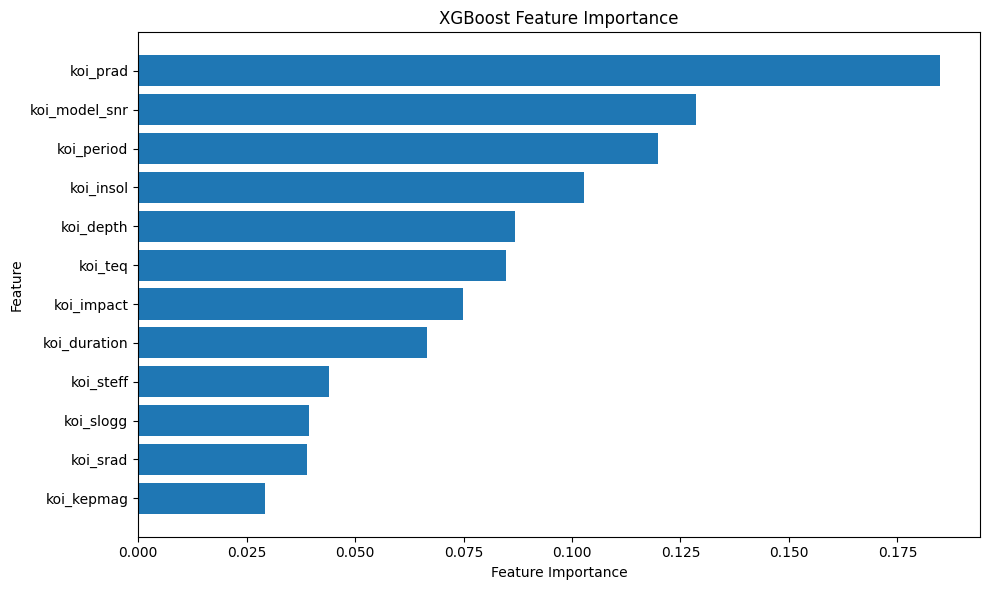

In [34]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Feature Importance Analysis

In terms of feature importance in the XGBoost model, the planetary radius (`koi_prad`) is the most important variable, followed by `koi_model_snr` and `koi_period`.

Planet parameters seem to play a bigger role in the predictions made by the model compared to stellar parameters like the effective temperature, surface gravity, and stellar radius.

## 13. Final Model Evaluation

In [35]:
test_predictions = tuned_xgb_model.predict(X_test)
test_probabilities = tuned_xgb_model.predict_proba(X_test)[:, 1]

print("Final Model: Tuned XGBoost")
print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(y_test, test_predictions))
print("Recall:", recall_score(y_test, test_predictions))
print("F1-score:", f1_score(y_test, test_predictions))
print("ROC-AUC:", roc_auc_score(y_test, test_probabilities))

Final Model: Tuned XGBoost
Accuracy: 0.9240506329113924
Precision: 0.8861003861003861
Recall: 0.8929961089494164
F1-score: 0.8895348837209303
ROC-AUC: 0.9722304353482432


### Confusion Matrix

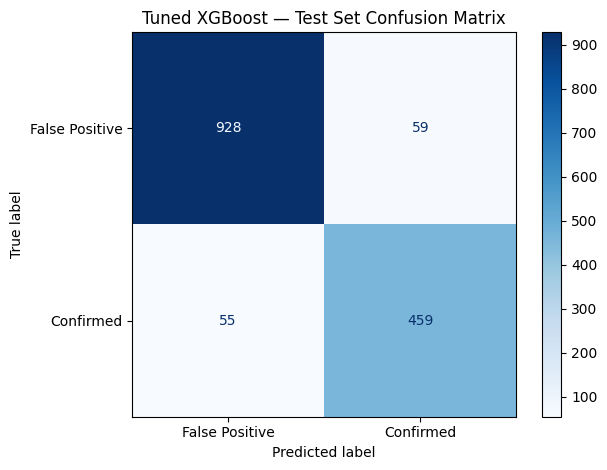

In [36]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["False Positive", "Confirmed"],
    cmap="Blues"
)

plt.title("Tuned XGBoost — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [37]:
print(classification_report(
    y_test,
    test_predictions,
    target_names=["False Positive", "Confirmed"]
))

                precision    recall  f1-score   support

False Positive       0.94      0.94      0.94       987
     Confirmed       0.89      0.89      0.89       514

      accuracy                           0.92      1501
     macro avg       0.92      0.92      0.92      1501
  weighted avg       0.92      0.92      0.92      1501



### Performance Summary

The tuned XGBoost model achieved **92.41% accuracy, an F1-score of 0.8895, and a ROC-AUC of 0.9722** on the test set.

With 88.61% precision, most observations classified as confirmed planets were correctly identified. Its 89.30% recall indicates that approximately 89% of confirmed planets in the test set were identified by the model.

Performance is slightly lower than on the validation set, but remains strong, suggesting that the model generalizes reasonably well to observations not used during training.

However, these results represent agreement with the classifications in the catalogue and do not independently confirm the existence of exoplanets.

## Saving the Final Model

In [38]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "kepler_xgboost.joblib"

joblib.dump(tuned_xgb_model, MODEL_PATH)

print(f"Model saved to: {MODEL_PATH}")

Model saved to: ../models/kepler_xgboost.joblib


In [39]:
loaded_model = joblib.load(MODEL_PATH)

sample_predictions = loaded_model.predict(X_test.iloc[:5])

print("Sample predictions:", sample_predictions)
print("Original predictions:", tuned_xgb_model.predict(X_test.iloc[:5]))

Sample predictions: [0 1 1 1 1]
Original predictions: [0 1 1 1 1]
